In [26]:
import os
import re
import math
import pandas as pd
import numpy as np

#This code processes Phyphox CSV files to extract statistical features from accelerometer and gyroscope data.
#It splits large CSV files into smaller chunks and computes mean, standard deviation, min, and max for each axis.

# --- FUNCTION DEFINITIONS ---

#CSV splitter
def split_csv_into_chunks(input_folder, output_folder=None, chunk_size=200, sep=';', decimal=','):
    if output_folder is None:
        output_folder = os.path.join(input_folder, 'snippets')
    os.makedirs(output_folder, exist_ok=True)

    for fname in os.listdir(input_folder):
        if not fname.lower().endswith('.csv'):
            continue
        in_path = os.path.join(input_folder, fname)
        try:
            df = pd.read_csv(in_path, sep=sep, decimal=decimal)
        except Exception as e:
            print(f"Skipping {fname}: read error: {e}")
            continue

        nrows = len(df)
        if nrows == 0:
            print(f"Skipping {fname}: empty file")
            continue

        base = os.path.splitext(fname)[0].replace(' ', '_')
        parts = math.ceil(nrows / chunk_size)
        for i in range(parts):
            start = i * chunk_size
            end = start + chunk_size
            chunk = df.iloc[start:end].copy()
            out_name = f"{base}_part{i+1:03d}.csv"
            out_path = os.path.join(output_folder, out_name)
            chunk.to_csv(out_path, index=False, sep=sep, decimal=decimal)
        print(f"Wrote {parts} chunks for {fname} -> {output_folder}")

    return output_folder

#Feature extractor
def extract_axis_features_from_folder(folder_path):
    features_list = []
    file_names = []
    action_list = []
    name_list = []

    col_labels = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']

    for file in os.listdir(folder_path):
        if file.endswith(".csv"):
            file_path = os.path.join(folder_path, file)
            try:
                df = pd.read_csv(file_path)
                if df.shape[1] >= 7:
                    data = df.iloc[:, 1:7]
                elif df.shape[1] == 6:
                    data = df.iloc[:, :6]
                else:
                    print(f"Skipping {file}: Not enough columns found ({df.shape[1]} columns).")
                    continue

                data = data.apply(pd.to_numeric, errors='coerce')
                if data.empty:
                    print(f"Skipping {file}: Data frame is empty after selection.")
                    continue

                means = data.mean().values
                stds = data.std().values
                mins = data.min().values
                maxs = data.max().values
                feature_vector = np.concatenate([means, stds, mins, maxs])

                features_list.append(feature_vector)
                file_names.append(file)

                # parse Action and Name from filename (handles underscores, spaces or dashes)
                base = os.path.splitext(file)[0]
                parts = re.split('[ _-]+', base)
                action = parts[0] if len(parts) >= 1 else ''
                name = parts[1] if len(parts) >= 2 else ''
                action_list.append(action)
                name_list.append(name)

            except Exception as e:
                print(f"Error processing {file}: {e}")

    stats = ['Mean', 'Std', 'Min', 'Max']
    final_headers = [f"{stat}_{col}" for stat in stats for col in col_labels]

    result_df = pd.DataFrame(features_list, columns=final_headers)
    result_df.insert(0, 'Action', action_list)
    result_df.insert(1, 'Name', name_list)

    return result_df

# --- USAGE SECTION ---

# 1. CHANGE THIS PATH to the folder containing your Phyphox CSV files
my_folder_path = './HumanActivity'

if os.path.exists(my_folder_path):

    # Split originals into snippets
    snippets_folder = split_csv_into_chunks('./HumanActivity', chunk_size=200)

    # 2. Run the functionfeature extractor
    features_df = extract_axis_features_from_folder(snippets_folder)

    # Print the result (First 5 rows)
    print("\nFeatures extracted successfully:")
    print(features_df.head())
    
    # 3. Optional: Save the features to a new CSV file ready for training
    output_file_name = 'extracted_features.csv'
    features_df.to_csv(output_file_name, index=False)
    print(f"\nFeatures saved to {output_file_name}")
else:
    print(f"ERROR: The specified folder path does not exist: {my_folder_path}")

Wrote 9 chunks for ChairSpin_Haakon.csv -> ./HumanActivity\snippets
Wrote 9 chunks for ChairSpin_Yvette.csv -> ./HumanActivity\snippets
Wrote 4 chunks for Jumping_Haakon.csv -> ./HumanActivity\snippets
Wrote 4 chunks for Jumping_Yvette.csv -> ./HumanActivity\snippets
Wrote 7 chunks for Squats_Haakon.csv -> ./HumanActivity\snippets
Wrote 11 chunks for Squats_Yvette.csv -> ./HumanActivity\snippets

Features extracted successfully:
      Action    Name  Mean_Acc_X  Mean_Acc_Y  Mean_Acc_Z  Mean_Gyro_X  \
0  ChairSpin  Haakon   -0.115424   -1.169192   -9.735004     0.052886   
1  ChairSpin  Haakon   -0.455341   -1.958385   -9.625230     0.047596   
2  ChairSpin  Haakon   -0.687627   -2.039453   -9.581057    -0.114867   
3  ChairSpin  Haakon   -0.205219   -1.987786   -9.660855     0.079128   
4  ChairSpin  Haakon   -0.165571   -2.046372   -9.638446    -0.060408   

   Mean_Gyro_Y  Mean_Gyro_Z  Std_Acc_X  Std_Acc_Y  ...  Min_Acc_Z  Min_Gyro_X  \
0    -0.012165    -1.191068   1.302610   1.3617

C:\Users\Véronique\AppData\Local\Temp\ipykernel_15972\640243575.py:42: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  raw = raw.applymap(lambda x: str(x).replace(',', '.'))
C:\Users\Véronique\AppData\Local\Temp\ipykernel_15972\640243575.py:42: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  raw = raw.applymap(lambda x: str(x).replace(',', '.'))
C:\Users\Véronique\AppData\Local\Temp\ipykernel_15972\640243575.py:42: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  raw = raw.applymap(lambda x: str(x).replace(',', '.'))
C:\Users\Véronique\AppData\Local\Temp\ipykernel_15972\640243575.py:42: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  raw = raw.applymap(lambda x: str(x).replace(',', '.'))
C:\Users\Véronique\AppData\Local\Temp\ipykernel_15972\640243575.py:42: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  raw =

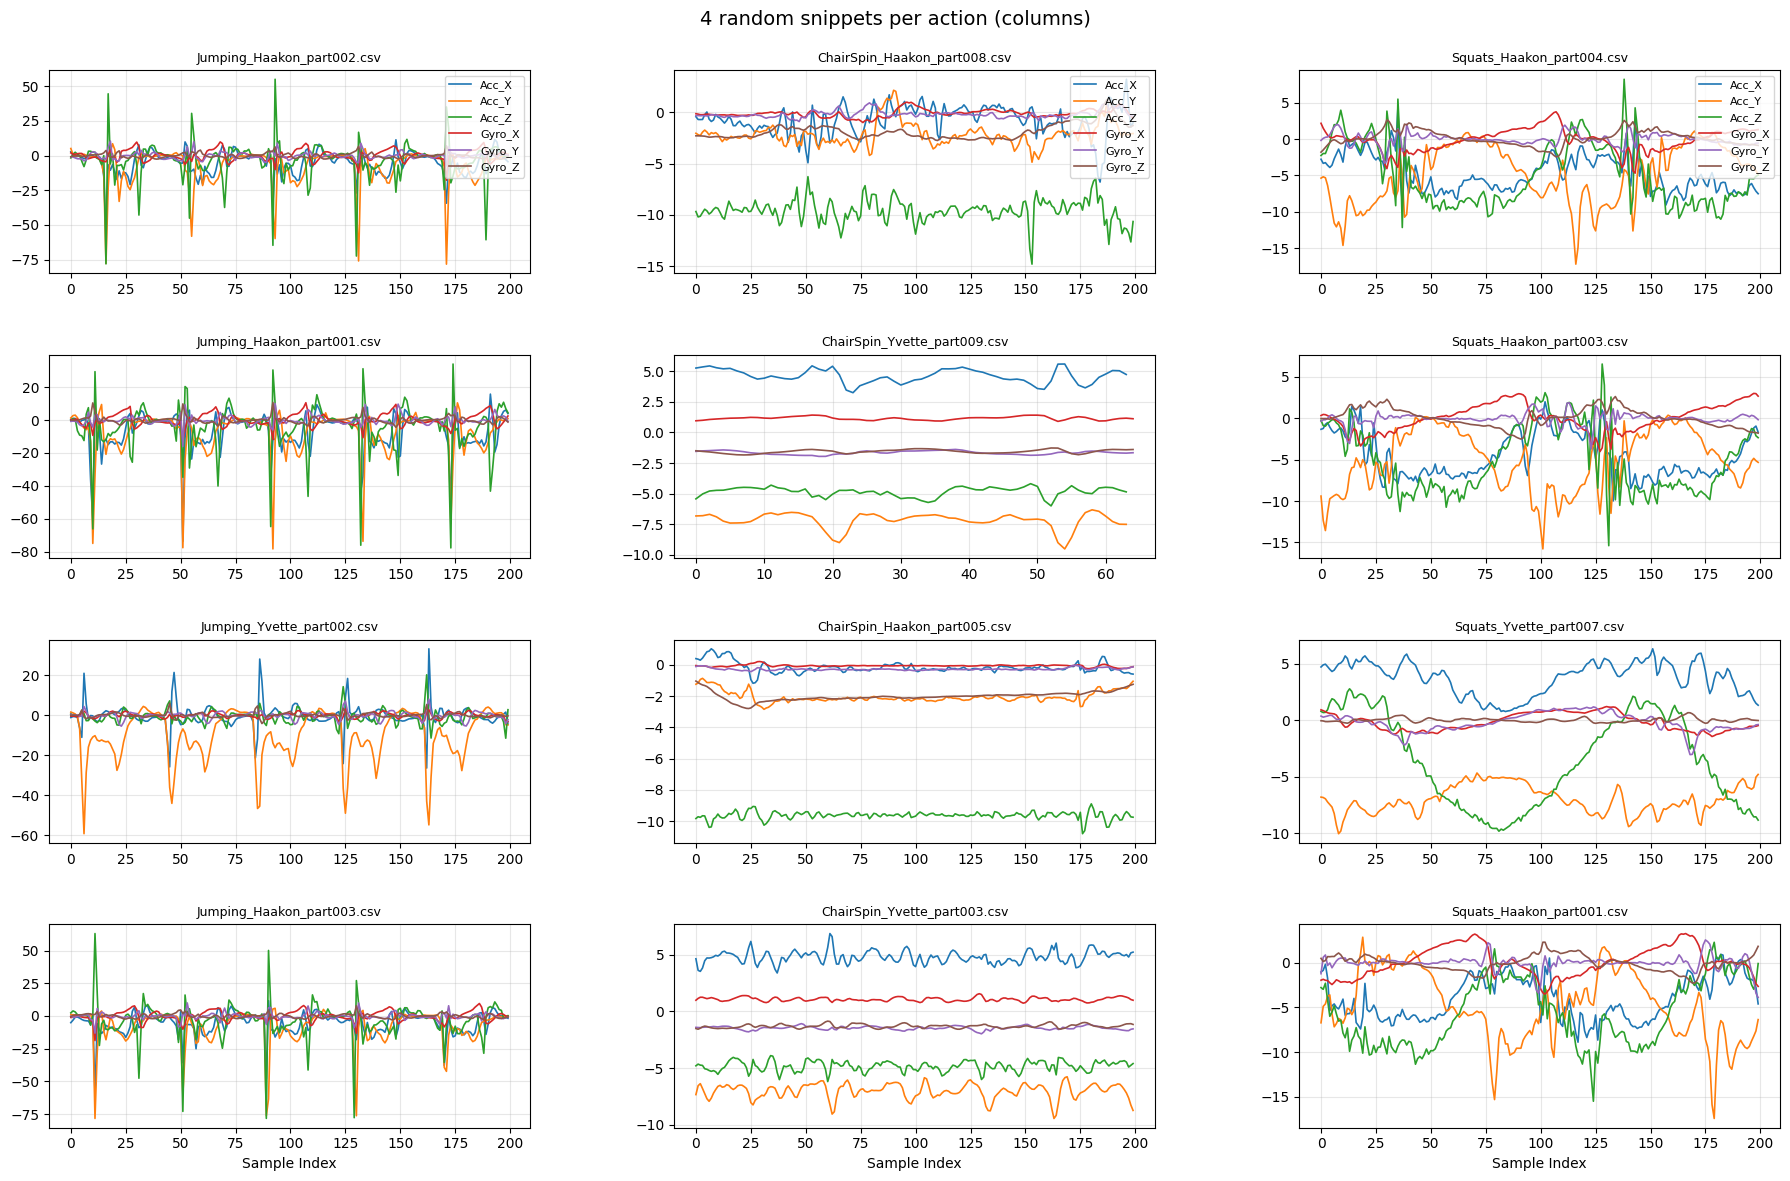

In [35]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

snippets_dir = './HumanActivity/snippets'
actions = ['Jumping', 'ChairSpin', 'Squats']   # matching text in filenames (case-insensitive)
per_action = 4

# gather files per action
files_by_action = {}
all_snippets = [f for f in os.listdir(snippets_dir) if f.endswith('.csv')]
for a in actions:
    matches = [f for f in all_snippets if a.lower() in f.lower()]
    files_by_action[a] = matches

# sample files (if fewer than required, take all available)
sampled = {a: random.sample(files_by_action[a], min(per_action, len(files_by_action[a])))
           for a in actions}

# plotting grid: 4 rows x 3 cols (rows = samples)
fig, axes = plt.subplots(per_action, len(actions), figsize=(18, 12), sharex=False)
axis_labels = ['Acc_X','Acc_Y','Acc_Z','Gyro_X','Gyro_Y','Gyro_Z']
colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown']

for col_idx, action in enumerate(actions):
    files = sampled[action]
    for row_idx in range(per_action):
        ax = axes[row_idx, col_idx] if per_action > 1 else axes[col_idx]
        if row_idx >= len(files):
            ax.axis('off')
            continue
        fname = files[row_idx]
        fpath = os.path.join(snippets_dir, fname)
        try:
            raw = pd.read_csv(fpath)                # read without explicit sep/decimal
            if raw.shape[1] == 1:
                raw = raw.iloc[:,0].astype(str).str.split(';', expand=True)
            # normalize decimals (comma -> dot) then convert to numeric
            raw = raw.applymap(lambda x: str(x).replace(',', '.'))
            if raw.shape[1] >= 7:
                data = raw.iloc[:, 1:7].copy()
            else:
                data = raw.iloc[:, :6].copy()
            data = data.apply(pd.to_numeric, errors='coerce')

            if data.shape[1] < 6:
                ax.text(0.5, 0.5, 'Not enough columns', ha='center', va='center')
                ax.set_title(fname)
                ax.axis('off')
                continue

            for i in range(6):
                label = axis_labels[i] if row_idx == 0 else None
                ax.plot(data.iloc[:, i].values, color=colors[i], label=label, linewidth=1.2)
            ax.set_title(fname, fontsize=9)
            if row_idx == 0:
                ax.legend(loc='upper right', fontsize=8)
            ax.grid(alpha=0.3)
            if row_idx == per_action - 1:
                ax.set_xlabel('Sample Index')
        except Exception as e:
            ax.text(0.5, 0.5, f'Error: {e}', ha='center', va='center')
            ax.set_title(fname)

plt.suptitle('4 random snippets per action (columns)', fontsize=14)
plt.tight_layout()
plt.subplots_adjust(top=0.93, hspace=0.4, wspace=0.3)
plt.show()

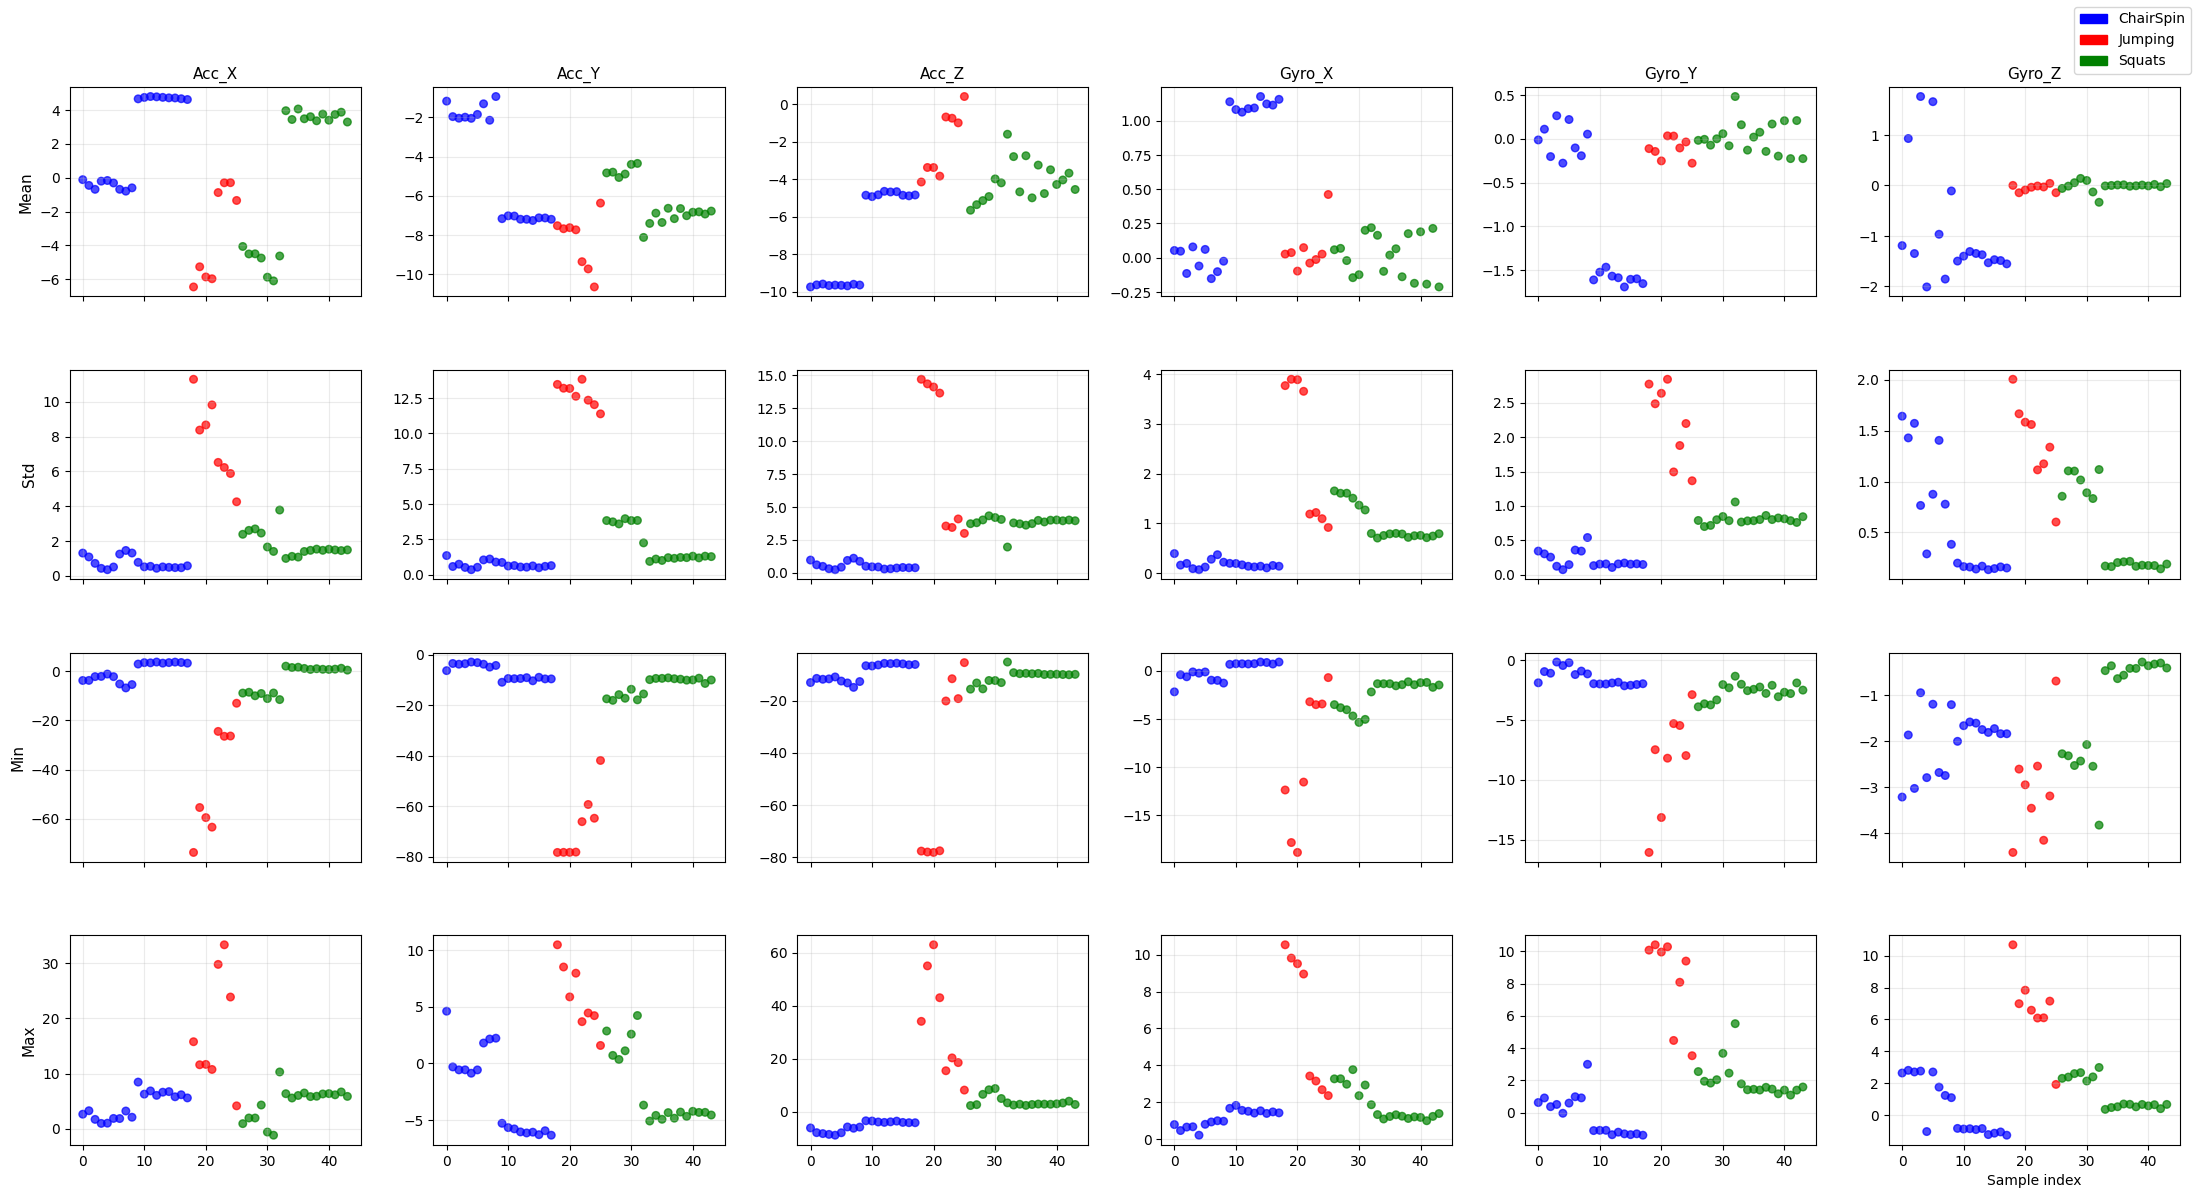

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# load
df = pd.read_csv('extracted_features.csv')

# order
stats = ['Mean', 'Std', 'Min', 'Max']
axes_labels = ['Acc_X','Acc_Y','Acc_Z','Gyro_X','Gyro_Y','Gyro_Z']

# colors by action (adjust if you have other action names)
action_colors = {'ChairSpin':'blue', 'Jumping':'red', 'Squats':'green'}
colors = [action_colors.get(a, 'gray') for a in df['Action']]

# make grid 4 rows x 6 cols
rows, cols = len(stats), len(axes_labels)
fig, axs = plt.subplots(rows, cols, figsize=(22, 12), sharex=True)
for r, stat in enumerate(stats):
    for c, ax_label in enumerate(axes_labels):
        colname = f"{stat}_{ax_label}"
        ax = axs[r, c]
        if colname in df.columns:
            ax.scatter(range(len(df)), pd.to_numeric(df[colname], errors='coerce'),
                       c=colors, s=30, alpha=0.7)
        else:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center')
        if r == 0:
            ax.set_title(ax_label, fontsize=11)
        if c == 0:
            ax.set_ylabel(stat, fontsize=11)
        ax.grid(alpha=0.25)
# common x label
axs[-1, -1].set_xlabel('Sample index')

# legend
legend_handles = [Patch(color=color, label=name) for name, color in action_colors.items()]
fig.legend(handles=legend_handles, loc='upper right', fontsize=10)

plt.tight_layout()
plt.subplots_adjust(top=0.93, hspace=0.35, wspace=0.25)
plt.show()